# Uber Fare Visualizations & Feature Analysis
This notebook uses **matplotlib** to visualize the cleaned Uber dataset (`uber_cleaned.csv`) and identify the most important features that affect fare amounts.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (8, 5)


In [ ]:
csv_path = 'uber_cleaned.csv'
if not os.path.exists(csv_path):
    for candidate in ['data_visualisations/uber_cleaned.csv', '../data_cleaning/uber_cleaned.csv', '../data_visualisations/uber_cleaned.csv']:
        if os.path.exists(candidate):
            csv_path = candidate
            break

df = pd.read_csv(csv_path)
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

print(f'Total rows: {len(df):,}')
print(f'Total columns: {len(df.columns)}')
df.head()


Total rows: 195,096
Total columns: 11


,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,year,month,hour,day_name
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,2015,5,19,Thursday
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,2009,7,20,Friday
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,2009,8,21,Monday
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,2009,6,8,Friday
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,2014,8,17,Thursday


### Feature Engineering: Calculate Trip Distance
Before visualizing, we calculate the trip distance (in km) between the pickup and dropoff coordinates using the Haversine formula.


In [ ]:
lat1, lon1 = np.radians(df['pickup_latitude']), np.radians(df['pickup_longitude'])
lat2, lon2 = np.radians(df['dropoff_latitude']), np.radians(df['dropoff_longitude'])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
a = np.clip(a, 0.0, 1.0)
df['distance_km'] = 6371 * 2 * np.arcsin(np.sqrt(a))

print(df[['fare_amount', 'distance_km']].head())


   fare_amount  distance_km
0          7.5     1.683323
1          7.7     2.457590
2         12.9     5.036377
3          5.3     1.661683
4         16.0     4.475450


---
## 1. Distribution of Fare Amount
We plot a histogram to examine how fare amounts are distributed across all rides.


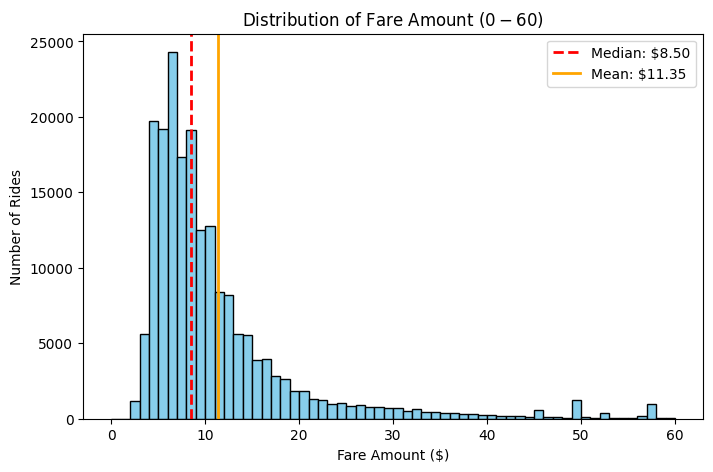

Median Fare: $8.50
Mean Fare:   $11.35
Min Fare:    $2.50
Max Fare:    $230.00


In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df['fare_amount'], bins=60, range=(0, 60), color='skyblue', edgecolor='black')

median_fare = df['fare_amount'].median()
mean_fare = df['fare_amount'].mean()
min_fare = df['fare_amount'].min()
max_fare = df['fare_amount'].max()

plt.axvline(median_fare, color='red', linestyle='--', linewidth=2, label=f'Median: ${median_fare:.2f}')
plt.axvline(mean_fare, color='orange', linestyle='-', linewidth=2, label=f'Mean: ${mean_fare:.2f}')

plt.title('Distribution of Fare Amount ($0 - $60)')
plt.xlabel('Fare Amount ($)')
plt.ylabel('Number of Rides')
plt.legend()
plt.show()

print(f'Median Fare: ${median_fare:.2f}')
print(f'Mean Fare:   ${mean_fare:.2f}')
print(f'Min Fare:    ${min_fare:.2f}')
print(f'Max Fare:    ${max_fare:.2f}')


### 📌 Important Features Observed:
- **Right-skewed distribution**: Most rides are short trips costing between **$6.00 and $12.50**. The median fare is **$8.50**.
- **Base fare minimum**: Fares strictly start at **$2.50**, which is the official NYC base flag-drop fee.
- **Outliers / Long trips**: Fares extend up to $300 for long-distance suburban trips and multi-hour rides.


---
## 2. Trip Distance vs. Fare Amount
We plot a scatter plot of trip distance versus fare amount to observe their relationship.


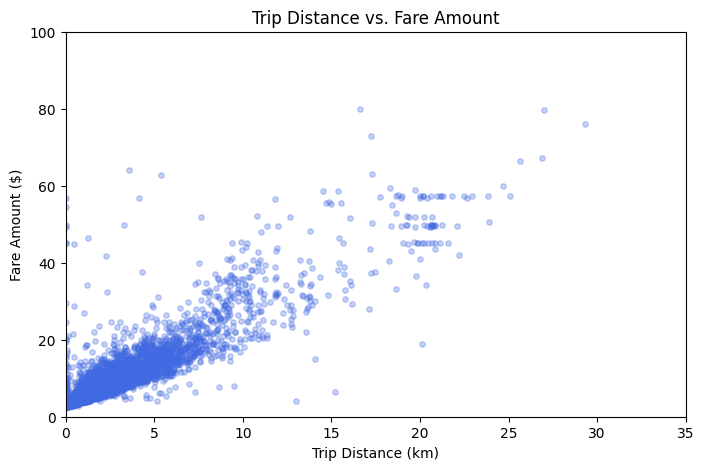

In [ ]:
sample = df.sample(5000, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(sample['distance_km'], sample['fare_amount'], alpha=0.3, s=15, color='royalblue')
plt.xlim(0, 35)
plt.ylim(0, 100)

plt.title('Trip Distance vs. Fare Amount')
plt.xlabel('Trip Distance (km)')
plt.ylabel('Fare Amount ($)')
plt.show()


### 📌 Important Features Observed:
- **Strong linear correlation**: As trip distance increases, the fare amount increases steadily. Distance is the most important feature for predicting fares.
- **Base fare intercept**: Even for near-zero distance trips, fares start around **$2.50 - $4.00**.
- **Airport flat-rate cluster**: A distinct horizontal band of points appears around **$45 - $55** at distances between 20-25 km, representing the fixed flat rate between Manhattan and JFK Airport.


---
## 3. Hourly Ride Demand (Time of Day)
We plot the number of rides across each hour of the day to identify peak demand hours.


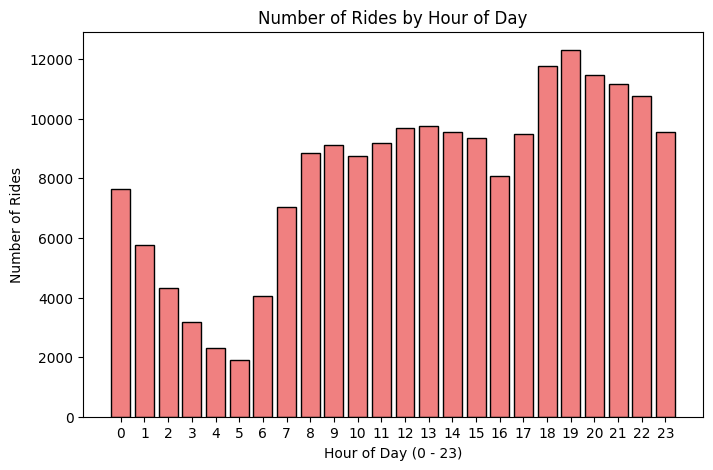

In [ ]:
rides_by_hour = df['hour'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(rides_by_hour.index, rides_by_hour.values, color='lightcoral', edgecolor='black')

plt.title('Number of Rides by Hour of Day')
plt.xlabel('Hour of Day (0 - 23)')
plt.ylabel('Number of Rides')
plt.xticks(range(0, 24))
plt.show()


### 📌 Important Features Observed:
- **Two peak demand periods**:
  1. **Morning Commute**: 8:00 AM – 9:00 AM (people commuting to offices).
  2. **Evening Rush (Highest Demand)**: 6:00 PM – 9:00 PM (commutes home, dining, and evening activities).
- **Lowest demand**: 3:00 AM – 5:00 AM when city activity is minimal.


---
## 4. Average Fare Amount by Hour of the Day
We analyze whether fare prices change across different hours of the day.


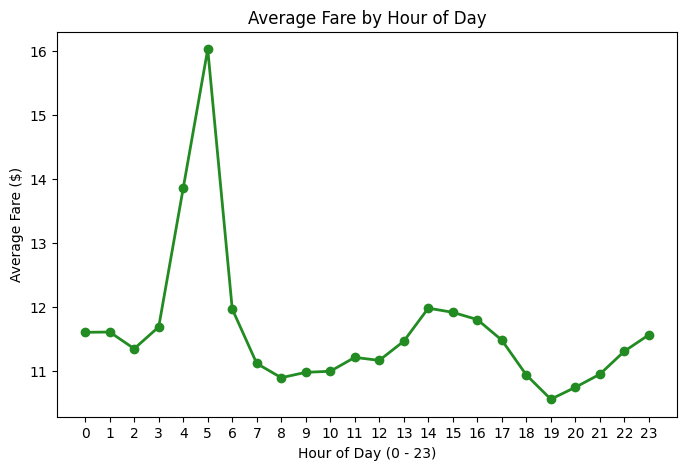

In [ ]:
avg_fare_by_hour = df.groupby('hour')['fare_amount'].mean()

plt.figure(figsize=(8, 5))
plt.plot(avg_fare_by_hour.index, avg_fare_by_hour.values, marker='o', color='forestgreen', linewidth=2)

plt.title('Average Fare by Hour of Day')
plt.xlabel('Hour of Day (0 - 23)')
plt.ylabel('Average Fare ($)')
plt.xticks(range(0, 24))
plt.show()


### 📌 Important Features Observed:
- **Early morning peak (4:00 AM – 5:00 AM)**: The average fare reaches its highest level (~**$12.50**) in the early morning. These trips are typically longer airport runs (catching morning flights) on uncongested roads.
- **Daytime stability**: Fares remain very consistent around **$11.00 - $11.30** from 9:00 AM to 5:00 PM.


---
## 5. Number of Rides by Day of the Week
We plot total rides across days of the week to reveal weekly habits.


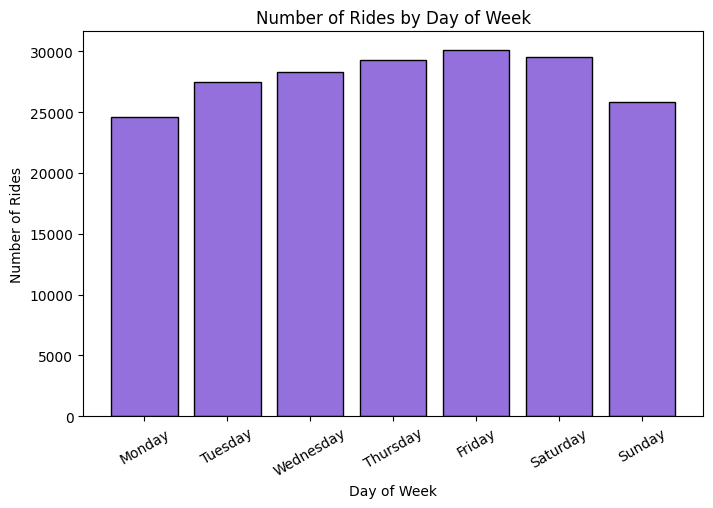

In [ ]:
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
rides_by_day = df['day_name'].value_counts().reindex(days_order)

plt.figure(figsize=(8, 5))
plt.bar(rides_by_day.index, rides_by_day.values, color='mediumpurple', edgecolor='black')

plt.title('Number of Rides by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Rides')
plt.xticks(rotation=30)
plt.show()


### 📌 Important Features Observed:
- **Rising volume towards the weekend**: Rides climb steadily from Monday (~25,000) to **Friday and Saturday** (~30,000+).
- **Weekend demand**: Friday and Saturday experience the highest volume due to social events, dinners, and nightlife.


---
## 6. Average Fare Amount by Day of the Week
We check if fares vary significantly by day of the week.


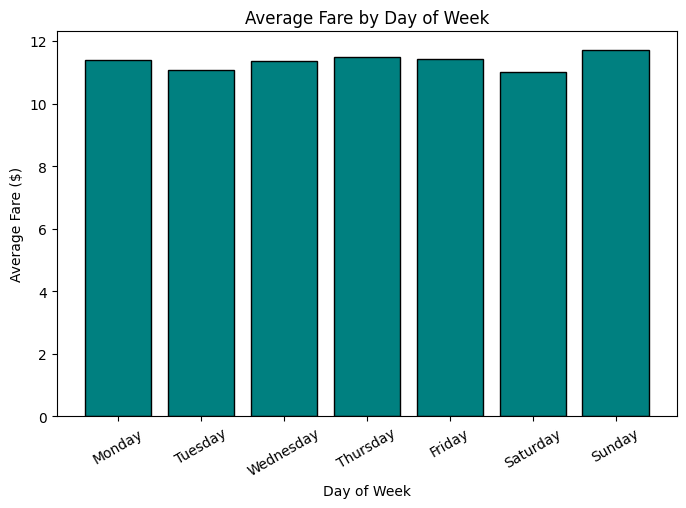

Monday: $11.39
Tuesday: $11.09
Wednesday: $11.36
Thursday: $11.50
Friday: $11.41
Saturday: $11.01
Sunday: $11.72


In [ ]:
avg_fare_by_day = df.groupby('day_name')['fare_amount'].mean().reindex(days_order)

plt.figure(figsize=(8, 5))
plt.bar(avg_fare_by_day.index, avg_fare_by_day.values, color='teal', edgecolor='black')

plt.title('Average Fare by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Fare ($)')
plt.xticks(rotation=30)
plt.show()

for day, fare in avg_fare_by_day.items():
    print(f'{day}: ${fare:.2f}')


### 📌 Important Features Observed:
- **Stable pricing across days**: Average fare stays nearly constant throughout the week between **$11.20 and $11.60**.
- **Sunday slightly higher**: Sunday has the highest average fare (~$11.60) due to longer leisure trips and airport returns.


---
## 7. Fare Trend Across Years (2009 - 2015)
We examine price inflation and regulatory increases over time.


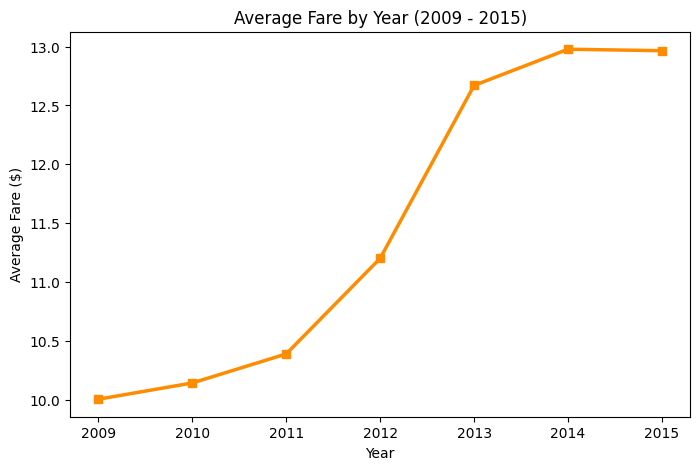

Year 2009: $10.01
Year 2010: $10.15
Year 2011: $10.39
Year 2012: $11.20
Year 2013: $12.67
Year 2014: $12.98
Year 2015: $12.96


In [ ]:
avg_fare_by_year = df.groupby('year')['fare_amount'].mean()

plt.figure(figsize=(8, 5))
plt.plot(avg_fare_by_year.index, avg_fare_by_year.values, marker='s', color='darkorange', linewidth=2.5)

plt.title('Average Fare by Year (2009 - 2015)')
plt.xlabel('Year')
plt.ylabel('Average Fare ($)')
plt.xticks(avg_fare_by_year.index)
plt.show()

for year, fare in avg_fare_by_year.items():
    print(f'Year {year}: ${fare:.2f}')


### 📌 Important Features Observed:
- **Steady price inflation**: Average fare increased from **$9.95 in 2009** to **$13.00 in 2015** (~30% increase).
- **2012 rate hike**: A sharp rise is visible between 2012 and 2013, corresponding to the September 2012 official NYC taxi rate increase.
- **Modeling takeaway**: `year` is an essential feature to capture price shifts over time.


---
## 8. Passenger Count Impact
We examine the distribution of passenger party sizes and its relationship with fare amount.


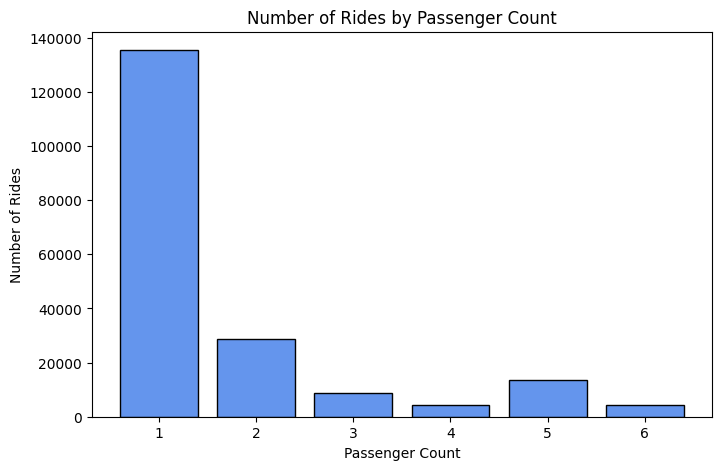

Average Fare by Passenger Count:
  1 Passenger(s): $11.23
  2 Passenger(s): $11.78
  3 Passenger(s): $11.43
  4 Passenger(s): $11.63
  5 Passenger(s): $11.20
  6 Passenger(s): $12.16


In [ ]:
passenger_counts = df['passenger_count'].value_counts().sort_index()
avg_fare_by_passenger = df.groupby('passenger_count')['fare_amount'].mean()

plt.figure(figsize=(8, 5))
plt.bar(passenger_counts.index, passenger_counts.values, color='cornflowerblue', edgecolor='black')

plt.title('Number of Rides by Passenger Count')
plt.xlabel('Passenger Count')
plt.ylabel('Number of Rides')
plt.xticks(passenger_counts.index)
plt.show()

print('Average Fare by Passenger Count:')
for count, fare in avg_fare_by_passenger.items():
    print(f'  {count} Passenger(s): ${fare:.2f}')


### 📌 Important Features Observed:
- **Solo passengers dominate**: About **70% of all rides have only 1 passenger**. Groups of 5 or 6 account for less than 9% combined.
- **Fare is independent of passenger count**: Average fare is virtually identical whether 1 passenger ($11.26) or 5 passengers ($11.20) are in the vehicle.
- **Modeling takeaway**: `passenger_count` has negligible predictive importance for fare prediction.


---
## 9. Pickup Locations Map (NYC Density)
We plot pickup coordinates on a scatter plot to observe spatial patterns.


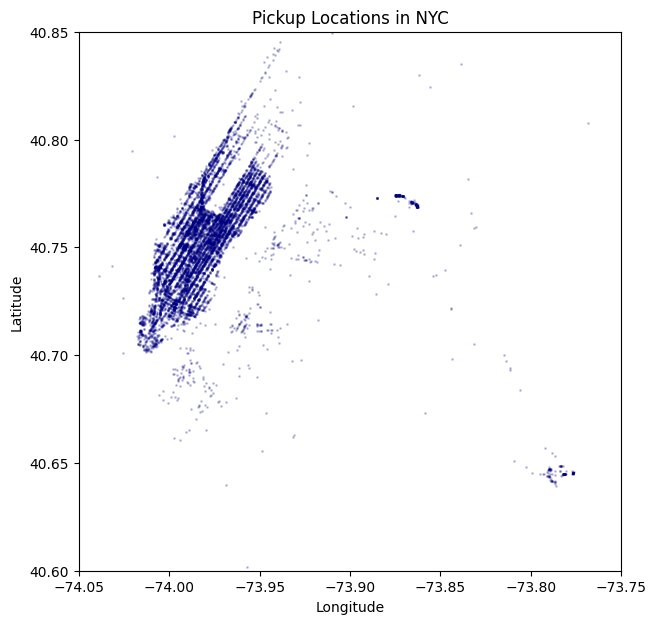

In [ ]:
sample_geo = df.sample(10000, random_state=42)

plt.figure(figsize=(7, 7))
plt.scatter(sample_geo['pickup_longitude'], sample_geo['pickup_latitude'], s=1, alpha=0.2, color='navy')

plt.xlim(-74.05, -73.75)
plt.ylim(40.60, 40.85)
plt.title('Pickup Locations in NYC')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()


### 📌 Important Features Observed:
- **Manhattan concentration**: The vast majority of pickups (>90%) are concentrated in Manhattan (the dense strip in the center-left).
- **Airport clusters**: Separate clusters on the right and bottom-right mark **LaGuardia Airport (LGA)** and **JFK Airport**.


---
## 10. Summary of Important Features for Fare Prediction

| Feature | Observed Pattern | Importance for Predicting Fare |
| :--- | :--- | :--- |
| **`distance_km`** | Strong direct linear relationship with fare amount. | **Most Important (Critical)** |
| **`pickup / dropoff coordinates`** | Most rides are in Manhattan; airport trips have fixed higher rates. | **High** |
| **`year`** | Fares rose ~30% from 2009 to 2015 due to rate hikes and inflation. | **Moderate** |
| **`hour`** | Demand peaks at 8-9 AM and 6-9 PM; highest average fares at 4-5 AM. | **Moderate** |
| **`day_name`** | Highest demand on Friday and Saturday; average fare remains stable. | **Low - Moderate** |
| **`passenger_count`** | ~70% are single passengers; fares do not change with passenger count. | **Low / Negligible** |
